# Semantic analysis by section + Morphological reconstruction

## Motivation

The constrained decipherment (Part VII) produced a glyph→Hebrew mapping with 100 biblical
roots detected (enrichment 154×), but n-grams worse than the baseline (percentile 5%).

This notebook addresses two complementary questions:

1. **Semantic analysis per section**: do the detected roots correlate with the
   thematic content of each Voynich section (herbal, astronomical, biological, etc.)?
2. **Morphological reconstruction**: does the mapping produce recognisable Hebrew words with
   the prefix-root-suffix structure characteristic of Biblical Hebrew?

If nature-related roots dominate in the herbal sections and astronomy-related roots
dominate in the astronomical sections, this would constitute an **independent semantic
validation** of the mapping. If article and preposition frequencies match Biblical Hebrew,
this would be additional **morphosyntactic evidence**.


In [1]:
import re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
from scipy.stats import chi2_contingency, fisher_exact

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

STA_PATH = 'corpus/voynich_sta.txt'
RESULTS_PATH = 'constrained_resultados.json'

# ── Global STA parser (from constrained Cell 2) ──

def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


# ── STA parser by section (from CDE_v2 Cell 4) ──

def construir_mapeo_secciones(filepath):
    folios_unicos = set()
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            matches = re.findall(r'<(f\d+[rv][ab]?\d*)>', linea)
            folios_unicos.update(matches)
    def folio_numero(tag):
        m = re.search(r'f(\d+)', tag)
        return int(m.group(1)) if m else 0
    def clasificar_folio(tag):
        n = folio_numero(tag)
        if   1  <= n <= 66:                       return 'herbal'
        elif 67 <= n <= 69:                       return 'astronomica'
        elif 70 <= n <= 73:                       return 'zodiaco'
        elif 74 <= n <= 84:                       return 'biologica'
        elif 85 <= n <= 87:                       return 'herbal'
        elif n in [88, 89] or 99 <= n <= 102:     return 'farmaceutica'
        elif 90 <= n <= 98:                       return 'herbal'
        elif 103 <= n <= 116:                     return 'recetas'
        else:                                     return 'desconocido'
    return {f: clasificar_folio(f) for f in folios_unicos}


def parsear_sta_con_secciones(filepath, mapeo_secciones):
    palabras_por_seccion = defaultdict(list)
    folio_actual = 'desconocido'
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            m_folio = re.match(r'^<(f\d+[rv][ab]?\d*)>', linea)
            if m_folio:
                folio_actual = m_folio.group(1)
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>', '', texto)
            texto = re.sub(r'-', '.', texto)
            if not texto:
                continue
            seccion = mapeo_secciones.get(folio_actual, 'desconocido')
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = [g for g in re.findall(r'[A-Z][0-9a-z]?', palabra_raw)
                          if len(g) == 2]
                if glifos:
                    palabras_por_seccion[seccion].append(glifos)
    return palabras_por_seccion


# ── Hebrew roots and matching functions (from validation Cell 9) ──

HEBREW_ROOTS = {
    'אמר', 'דבר', 'היה', 'בוא', 'עשה', 'נתן', 'ידע', 'הלך', 'ראה', 'שמע',
    'אכל', 'לקח', 'ישב', 'קרא', 'שלח', 'עלה', 'מות', 'שוב', 'ברך', 'יצא',
    'עבר', 'שמר', 'כתב', 'נשא', 'זכר', 'ילד', 'עמד', 'פנה', 'בנה', 'נפל',
    'שים', 'חיה', 'גדל', 'קום', 'מלא', 'מצא', 'שפט', 'אהב', 'ירד', 'נגד',
    'יסף', 'חטא', 'קדש', 'כהן', 'צוה', 'ברא', 'גלה', 'זבח', 'טהר', 'טמא',
    'ארץ', 'בית', 'שנה', 'יום', 'מים', 'שמש', 'ליל', 'אבן', 'עיר', 'דרך',
    'מלך', 'כסף', 'זהב', 'דמם', 'רוח', 'נפש', 'לחם', 'עין', 'ידד', 'שדה',
    'עבד', 'כלי', 'פרי', 'חדש', 'ספר', 'עצם', 'בשר', 'אדם', 'נהר', 'גבר',
    'רגל', 'ראש', 'חזק', 'רבב', 'קטן', 'טוב', 'רעע', 'חכם', 'צדק', 'רחם',
    'כול', 'בקר', 'צאן', 'עוף', 'דגג', 'שמן', 'יין', 'סוס', 'גמל', 'חמר',
}

HEBREW_CONSONANTS_SET = set('בגדהוזחטיכלמנסעפצקרשת') | set('ךםןףץ')
HEBREW_MATRES = set('אוי')


def extract_skeleton(mapped_word, confidences, conf_threshold=0.70,
                     glyph_word=None):
    skeleton = []
    for i, char in enumerate(mapped_word):
        if char in HEBREW_MATRES:
            continue
        if char not in HEBREW_CONSONANTS_SET:
            continue
        if glyph_word and i < len(glyph_word):
            g = glyph_word[i]
            conf = confidences.get(g, 0)
            if conf < conf_threshold:
                skeleton.append('*')
            else:
                skeleton.append(char)
        else:
            skeleton.append(char)
    return ''.join(skeleton)


def match_skeleton_to_root(skeleton, root):
    if len(skeleton) != len(root):
        return False
    for s, r in zip(skeleton, root):
        if s == '*':
            continue
        if s != r:
            return False
    return True


# ── Auxiliary function: apply mapping to a word ──

def aplicar_mapping(glyph_word, mapping):
    return ''.join(mapping.get(g, '?') for g in glyph_word)


print("Functions loaded successfully.")
print(f"  Hebrew roots: {len(HEBREW_ROOTS)}")

Functions loaded successfully.
  Hebrew roots: 100


In [2]:
# ── Load global corpus ──
tokens = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens)
print(f"Corpus global: {len(palabras)} words, {len(tokens)} tokens")

# ── Load by section ──
mapeo_secciones = construir_mapeo_secciones(STA_PATH)
palabras_por_seccion = parsear_sta_con_secciones(STA_PATH, mapeo_secciones)

SECCIONES_ORDEN = ['herbal', 'astronomica', 'zodiaco', 'biologica', 'farmaceutica', 'recetas']
print("\nWords per section:")
total_sec = 0
for sec in SECCIONES_ORDEN:
    n = len(palabras_por_seccion[sec])
    total_sec += n
    print(f"  {sec:15s}: {n:6d}")
if 'desconocido' in palabras_por_seccion:
    n_desc = len(palabras_por_seccion['desconocido'])
    total_sec += n_desc
    print(f"  {'desconocido':15s}: {n_desc:6d}")
print(f"  {'TOTAL':15s}: {total_sec:6d}")

# ── Load constrained mapping and posteriors ──
with open(RESULTS_PATH) as f:
    constrained = json.load(f)

mapping = constrained['mapping']
posterior = constrained['posterior']

# Compute confidence scores
confianzas = {}
for g, dist in posterior.items():
    confianzas[g] = max(dist.values())

conf_vals = list(confianzas.values())
print(f"\nMapping: {len(mapping)} glyphs")
print(f"Confidence: mean={np.mean(conf_vals):.3f}, median={np.median(conf_vals):.3f}")
print(f"  >= 0.7: {sum(1 for v in conf_vals if v >= 0.7)}/{len(conf_vals)}")
print(f"  >= 0.5: {sum(1 for v in conf_vals if v >= 0.5)}/{len(conf_vals)}")
print(f"  >= 0.3: {sum(1 for v in conf_vals if v >= 0.3)}/{len(conf_vals)}")

Corpus global: 37087 words, 194341 tokens

Words per section:
  herbal         :  14278
  astronomica    :   1342
  zodiaco        :   1588
  biologica      :   6768
  farmaceutica   :   2505
  recetas        :  10606
  TOTAL          :  37087

Mapping: 166 glyphs
Confidence: mean=0.257, median=0.155
  >= 0.7: 15/166
  >= 0.5: 27/166
  >= 0.3: 35/166


## Analysis 1 — Roots by section

Do the biblical roots detected by the constrained mapping distribute differentially
across the manuscript's sections? If the mapping captures real semantics,
we would expect to see flora/fauna roots concentrated in the herbal section,
astronomical roots in the astronomical section, etc.


In [3]:
# ── Root matching by section ──
# We use conf_threshold=0.30 (more permissive than 0.70) because the median
# confidence of the mapping is ~0.15. With 0.70, almost everything would be wildcard.

CONF_THRESHOLD = 0.30

def root_matching_seccion(palabras_sec, mapping, confianzas, threshold=CONF_THRESHOLD):
    roots_encontradas = Counter()
    total_matcheable = 0

    for glyph_word in palabras_sec:
        mapped = aplicar_mapping(glyph_word, mapping)
        skeleton = extract_skeleton(mapped, confianzas, conf_threshold=threshold,
                                     glyph_word=glyph_word)
        if len(skeleton) < 2:
            continue
        total_matcheable += 1

        for root in HEBREW_ROOTS:
            # Try matching at any position (the root may be
            # preceded by prefixes or followed by suffixes)
            for start in range(len(skeleton) - len(root) + 1):
                sub = skeleton[start:start+len(root)]
                if match_skeleton_to_root(sub, root):
                    roots_encontradas[root] += 1
                    break  # once per word per root

    return roots_encontradas, total_matcheable


# ── Global root matching (reference) ──
roots_global, total_global = root_matching_seccion(palabras, mapping, confianzas)
print(f"Root matching global: {len(roots_global)} distinct roots in {total_global} words")
print(f"  Total matches: {sum(roots_global.values())}")

# ── Root matching by section ──
roots_por_seccion = {}
totales_por_seccion = {}

for sec in SECCIONES_ORDEN:
    roots_sec, total_sec = root_matching_seccion(
        palabras_por_seccion[sec], mapping, confianzas
    )
    roots_por_seccion[sec] = roots_sec
    totales_por_seccion[sec] = total_sec
    print(f"\n{sec}: {len(roots_sec)} distinct roots, "
          f"{sum(roots_sec.values())} matches in {total_sec} words")
    top5 = roots_sec.most_common(5)
    print(f"  Top 5: {', '.join(f'{r}({c})' for r,c in top5)}")

# ── Verify that section roots cover the global set ──
all_roots_from_sections = set()
for sec in SECCIONES_ORDEN:
    all_roots_from_sections.update(roots_por_seccion[sec].keys())
print(f"\nRoots found across sections: {len(all_roots_from_sections)}")
print(f"Global roots: {len(roots_global)}")

Root matching global: 100 distinct roots in 36195 words
  Total matches: 4215

herbal: 53 distinct roots, 1514 matches in 13777 words
  Top 5: שמר(650), שמע(386), עמד(113), שמש(57), מות(49)

astronomica: 100 distinct roots, 247 matches in 1307 words
  Top 5: שמע(39), עמד(24), שמר(18), שמש(12), מות(12)

zodiaco: 17 distinct roots, 159 matches in 1558 words
  Top 5: שמע(47), שמר(46), חמר(14), שמש(9), עמד(7)

biologica: 15 distinct roots, 660 matches in 6661 words
  Top 5: שמע(385), שמר(204), עלה(22), עמד(15), מות(7)

farmaceutica: 22 distinct roots, 166 matches in 2444 words
  Top 5: שמר(39), שמע(38), עמד(26), מות(15), שמש(13)

recetas: 28 distinct roots, 1469 matches in 10448 words
  Top 5: שמר(628), שמע(584), עמד(71), חמר(42), בית(30)

Roots found across sections: 100
Global roots: 100


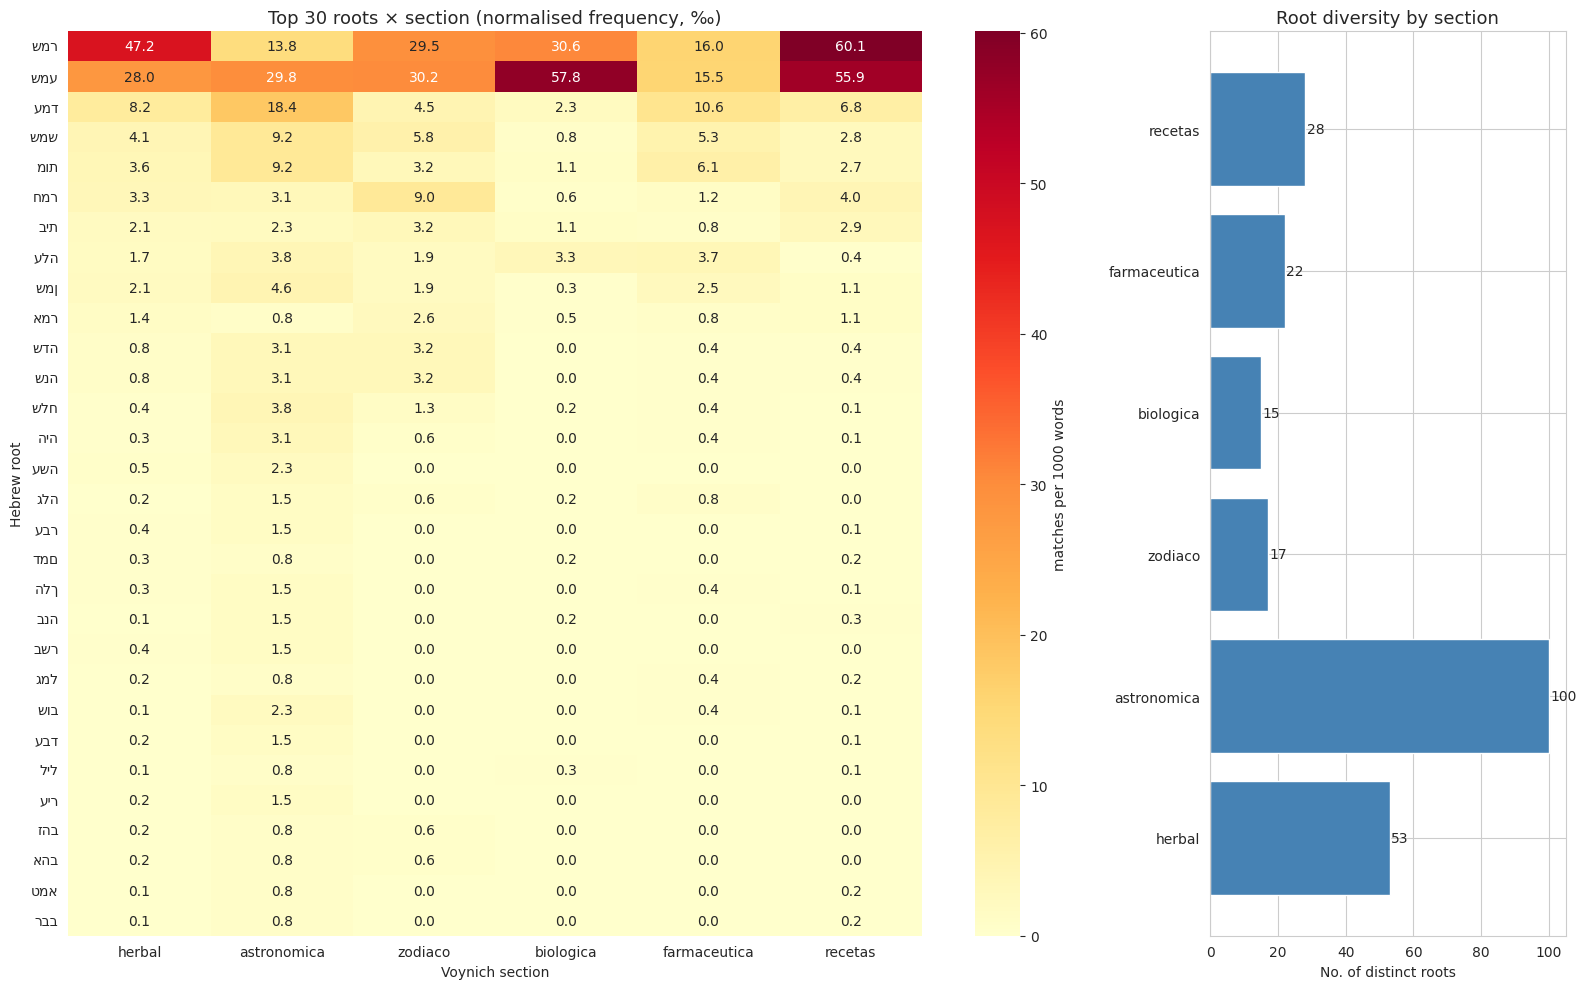


── Roots with high section specificity ──
(ratio = section_freq_normalised / global_freq_normalised > 1.5)

     seccion raiz  count_sec  count_global     ratio
 astronomica  שפט          3             5 16.615914
 astronomica  שים          3             5 16.615914
 astronomica  שוב          3             7 11.868510
 astronomica  היה          4            11 10.070251
 astronomica  שלח          5            16  8.654122
 astronomica  עשה          3            10  8.307957
     zodiaco  שדה          5            25  4.646341
     zodiaco  שנה          5            25  4.646341
 astronomica  שנה          4            25  4.430910
 astronomica  שדה          4            25  4.430910
     zodiaco  חמר         14           113  2.878265
 astronomica  מות         12           116  2.864813
 astronomica  שמן          6            58  2.864813
 astronomica  שמש         12           125  2.658546
 astronomica  עמד         24           256  2.596237
     zodiaco  אמר          4            40 

In [4]:
# ── Heatmap: top-30 roots × 6 sections ──

# Select top-30 roots by global frequency
top_roots = [r for r, _ in roots_global.most_common(30)]

# Build matrix
matrix = np.zeros((len(top_roots), len(SECCIONES_ORDEN)))
for j, sec in enumerate(SECCIONES_ORDEN):
    n_sec = totales_por_seccion[sec]
    for i, root in enumerate(top_roots):
        count = roots_por_seccion[sec].get(root, 0)
        matrix[i, j] = count / n_sec * 1000 if n_sec > 0 else 0  # per thousand

df_heatmap = pd.DataFrame(matrix, index=top_roots, columns=SECCIONES_ORDEN)

fig, axes = plt.subplots(1, 2, figsize=(16, 10), gridspec_kw={'width_ratios': [3, 1]})

# Heatmap
ax = axes[0]
sns.heatmap(df_heatmap, annot=True, fmt='.1f', cmap='YlOrRd',
            ax=ax, cbar_kws={'label': 'matches per 1000 words'})
ax.set_title('Top 30 roots × section (normalised frequency, ‰)', fontsize=13)
ax.set_ylabel('Hebrew root')
ax.set_xlabel('Voynich section')

# Barplot: number of distinct roots per section
ax2 = axes[1]
n_roots = [len(roots_por_seccion[sec]) for sec in SECCIONES_ORDEN]
bars = ax2.barh(SECCIONES_ORDEN, n_roots, color='steelblue')
ax2.set_xlabel('No. of distinct roots')
ax2.set_title('Root diversity by section', fontsize=13)
for bar, val in zip(bars, n_roots):
    ax2.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             str(val), va='center', fontsize=10)

plt.tight_layout()
plt.savefig('images/semantic_heatmap_raices.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Section-specific roots ──
print("\n── Roots with high section specificity ──")
print("(ratio = section_freq_normalised / global_freq_normalised > 1.5)\n")

especificidad_data = []
for sec in SECCIONES_ORDEN:
    n_sec = totales_por_seccion[sec]
    n_global = total_global
    for root in roots_por_seccion[sec]:
        freq_sec = roots_por_seccion[sec][root] / n_sec if n_sec > 0 else 0
        freq_glob = roots_global.get(root, 0) / n_global if n_global > 0 else 0
        if freq_glob > 0:
            ratio = freq_sec / freq_glob
        else:
            ratio = 0
        if ratio > 1.5 and roots_por_seccion[sec][root] >= 3:
            especificidad_data.append({
                'seccion': sec,
                'raiz': root,
                'count_sec': roots_por_seccion[sec][root],
                'count_global': roots_global.get(root, 0),
                'ratio': ratio
            })

df_esp = pd.DataFrame(especificidad_data)
if len(df_esp) > 0:
    df_esp = df_esp.sort_values('ratio', ascending=False)
    print(df_esp.to_string(index=False))
else:
    print("No roots with high specificity were found.")

── Counts: semantic category × section ──
                     herbal  astronomica  zodiaco  biologica  farmaceutica  recetas
botanica_naturaleza      67           23       11         24            17       22
astronomia_tiempo        70           21       14          7            14       34
cuerpo_biologia          11           12        0          1             0        2
religion_ritual           6            7        0          0             0        3
sociedad_material        38           11        6          7             2       31

── Enrichment: semantic category × section ──
(ratio = freq_section / freq_global; >1 = enriched, <1 = depleted)
                     herbal  astronomica  zodiaco  biologica  farmaceutica  recetas
botanica_naturaleza   1.073        3.884    1.558      0.795         1.535    0.465
astronomia_tiempo     1.149        3.635    2.033      0.238         1.296    0.736
cuerpo_biologia       1.112       12.781    0.000      0.209         0.000    0.266
reli

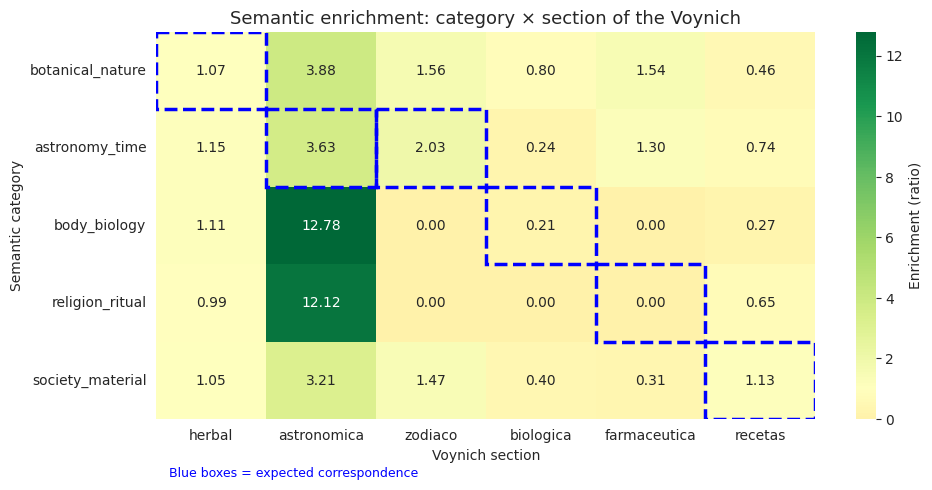


── Chi-squared test: semantic_category × section association ──
Chi² = 64.21, p = 1.5600e-06, dof = 20
→ Significant association (p < 0.05)

── Verification of expected correspondences ──
  herbal          ↔ botanica_naturaleza      : enrichment=1.073 (n=67) ✓
  astronomica     ↔ astronomia_tiempo        : enrichment=3.635 (n=21) ✓
  zodiaco         ↔ astronomia_tiempo        : enrichment=2.033 (n=14) ✓
  biologica       ↔ cuerpo_biologia          : enrichment=0.209 (n=1) ✗
  farmaceutica    ↔ religion_ritual          : enrichment=0.000 (n=0) ✗
  recetas         ↔ sociedad_material        : enrichment=1.130 (n=31) ✓

Correspondences met: 4/6


In [5]:
# ── Semantic correlation test ──

# Define expected semantic categories
CATEGORIAS_SEMANTICAS = {
    'botanica_naturaleza': {
        'פרי', 'שדה', 'עוף', 'צאן', 'עלה', 'גמל', 'סוס', 'דגג', 'שמן', 'יין'
    },
    'astronomia_tiempo': {
        'יום', 'שמש', 'ליל', 'חדש', 'שנה', 'רוח'
    },
    'cuerpo_biologia': {
        'נפש', 'בשר', 'עצם', 'רגל', 'ראש', 'עין', 'רחם', 'חיה', 'דמם'
    },
    'religion_ritual': {
        'קדש', 'כהן', 'זבח', 'טהר', 'טמא', 'ברך', 'צדק'
    },
    'sociedad_material': {
        'מלך', 'בית', 'עיר', 'כסף', 'זהב', 'אבן', 'כלי', 'ספר'
    }
}

# Expected correspondence hypotheses
CORRESPONDENCIAS = {
    'herbal': 'botanica_naturaleza',
    'astronomica': 'astronomia_tiempo',
    'zodiaco': 'astronomia_tiempo',
    'biologica': 'cuerpo_biologia',
    'farmaceutica': 'religion_ritual',
    'recetas': 'sociedad_material',
}

# ── Compute enrichment by category × section ──
cat_names = list(CATEGORIAS_SEMANTICAS.keys())

enrichment_matrix = np.zeros((len(cat_names), len(SECCIONES_ORDEN)))
count_matrix = np.zeros((len(cat_names), len(SECCIONES_ORDEN)))

for j, sec in enumerate(SECCIONES_ORDEN):
    n_sec = totales_por_seccion[sec]
    for i, cat in enumerate(cat_names):
        cat_roots = CATEGORIAS_SEMANTICAS[cat]
        count_sec = sum(roots_por_seccion[sec].get(r, 0) for r in cat_roots)
        count_global = sum(roots_global.get(r, 0) for r in cat_roots)
        count_matrix[i, j] = count_sec

        if n_sec > 0 and total_global > 0 and count_global > 0:
            freq_sec = count_sec / n_sec
            freq_glob = count_global / total_global
            enrichment_matrix[i, j] = freq_sec / freq_glob
        else:
            enrichment_matrix[i, j] = 0

df_enrichment = pd.DataFrame(enrichment_matrix, index=cat_names, columns=SECCIONES_ORDEN)
df_counts = pd.DataFrame(count_matrix.astype(int), index=cat_names, columns=SECCIONES_ORDEN)

# Display-friendly English names for plot axes
_display_names = {
    'botanica_naturaleza': 'botanical_nature',
    'astronomia_tiempo': 'astronomy_time',
    'cuerpo_biologia': 'body_biology',
    'religion_ritual': 'religion_ritual',
    'sociedad_material': 'society_material',
}
df_enrichment_display = df_enrichment.rename(index=_display_names)

print("── Counts: semantic category × section ──")
print(df_counts.to_string())
print()

print("── Enrichment: semantic category × section ──")
print("(ratio = freq_section / freq_global; >1 = enriched, <1 = depleted)")
print(df_enrichment.round(3).to_string())

# ── Enrichment heatmap ──
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(df_enrichment_display, annot=True, fmt='.2f', cmap='RdYlGn', center=1.0,
            ax=ax, cbar_kws={'label': 'Enrichment (ratio)'})
ax.set_title('Semantic enrichment: category × section of the Voynich', fontsize=13)
ax.set_ylabel('Semantic category')
ax.set_xlabel('Voynich section')

# Mark expected correspondences with boxes
for sec, cat_esperada in CORRESPONDENCIAS.items():
    j = SECCIONES_ORDEN.index(sec)
    i = cat_names.index(cat_esperada)
    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor='blue',
                                linewidth=2.5, linestyle='--'))

ax.text(0.02, -0.15, 'Blue boxes = expected correspondence',
        transform=ax.transAxes, fontsize=9, color='blue')
plt.tight_layout()
plt.savefig('images/semantic_enrichment_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Chi-squared: semantic category × section association ──
print("\n── Chi-squared test: semantic_category × section association ──")
chi2, p_val, dof, expected = chi2_contingency(count_matrix)
print(f"Chi² = {chi2:.2f}, p = {p_val:.4e}, dof = {dof}")
if p_val < 0.05:
    print("→ Significant association (p < 0.05)")
else:
    print("→ No significant association (p >= 0.05)")

# ── Verify individual correspondences ──
print("\n── Verification of expected correspondences ──")
correspondencia_resultados = []
for sec, cat_esperada in CORRESPONDENCIAS.items():
    j = SECCIONES_ORDEN.index(sec)
    i = cat_names.index(cat_esperada)
    enr = enrichment_matrix[i, j]
    cnt = int(count_matrix[i, j])
    valido = enr > 1.0
    correspondencia_resultados.append({
        'seccion': sec,
        'categoria_esperada': cat_esperada,
        'enrichment': round(enr, 3),
        'count': cnt,
        'cumple': '✓' if valido else '✗'
    })
    print(f"  {sec:15s} ↔ {cat_esperada:25s}: enrichment={enr:.3f} "
          f"(n={cnt}) {'✓' if valido else '✗'}")

n_cumplen = sum(1 for r in correspondencia_resultados if r['cumple'] == '✓')
print(f"\nCorrespondences met: {n_cumplen}/{len(correspondencia_resultados)}")


## Analysis 2 — Morphological reconstruction

Does the constrained mapping produce Hebrew words with recognisable morphological structure?

Biblical Hebrew has a well-defined morphology:
- **Proclitic prefixes**: ה (article), ב (in), כ (as/like), ל (to/for), מ (from)
- **Triconsonantal root**: semantic base of 3 consonants
- **Suffixes**: ה (feminine), ת (feminine/verbal), ם (masc. plural), ן, ך

If the mapping is linguistically valid, we should see:
1. Words decomposable into prefix + root + suffix
2. Article ה frequency ~15–18% (as in real Biblical Hebrew)
3. Prepositions ב, כ, ל, מ with coherent frequencies


In [6]:
# ── Morphological reconstruction: top-200 words ──

# Proclitic prefixes of Biblical Hebrew
PREFIJOS_HEBREOS = {'ה', 'ב', 'כ', 'ל', 'מ'}

# Common nominal/verbal suffixes
SUFIJOS_HEBREOS = {
    'ה': 'fem.sg / directive',
    'ת': 'fem.sg / 2nd pers.',
    'ם': 'masc.pl',
    'ן': 'verbal suffix',
    'ך': '2nd pers.sg',
    'ות': 'fem.pl',
    'ים': 'masc.pl',
}

# Count word frequencies (as glyph tuples)
word_counts = Counter(tuple(w) for w in palabras)
top200 = word_counts.most_common(200)

print(f"Analysing the {len(top200)} most frequent words")
print(f"(covering {sum(c for _,c in top200)}/{len(palabras)} = "
      f"{sum(c for _,c in top200)/len(palabras)*100:.1f}% of the corpus)\n")

# ── Analyse morphological structure ──
analisis_morfo = []

for glyph_tuple, count in top200:
    glyph_word = list(glyph_tuple)
    mapped = aplicar_mapping(glyph_word, mapping)

    # Detect prefix
    prefijo = ''
    cuerpo = mapped
    if len(mapped) > 1 and mapped[0] in PREFIJOS_HEBREOS:
        prefijo = mapped[0]
        cuerpo = mapped[1:]

    # Detect suffix (2 chars first, then 1)
    sufijo = ''
    if len(cuerpo) > 2 and cuerpo[-2:] in SUFIJOS_HEBREOS:
        sufijo = cuerpo[-2:]
        cuerpo = cuerpo[:-2]
    elif len(cuerpo) > 1 and cuerpo[-1] in SUFIJOS_HEBREOS:
        sufijo = cuerpo[-1]
        cuerpo = cuerpo[:-1]

    # Search for triconsonantal root in the body
    consonantes = [c for c in cuerpo if c in HEBREW_CONSONANTS_SET and c not in HEBREW_MATRES]
    raiz_encontrada = ''
    cons_str = ''.join(consonantes)
    for root in HEBREW_ROOTS:
        for start in range(len(cons_str) - len(root) + 1):
            if cons_str[start:start+len(root)] == root:
                raiz_encontrada = root
                break
        if raiz_encontrada:
            break

    # Classify
    if raiz_encontrada and (prefijo or sufijo):
        categoria = 'completa'
    elif raiz_encontrada:
        categoria = 'raiz_parcial'
    elif prefijo or sufijo:
        categoria = 'morfologia_solo'
    else:
        categoria = 'no_reconocible'

    analisis_morfo.append({
        'glifos': '.'.join(glyph_word),
        'hebreo': mapped,
        'prefijo': prefijo,
        'cuerpo': cuerpo,
        'sufijo': sufijo,
        'raiz': raiz_encontrada,
        'categoria': categoria,
        'freq': count,
    })

df_morfo = pd.DataFrame(analisis_morfo)

# ── Category summary ──
print("── Distribution of morphological categories ──")
cat_counts = df_morfo['categoria'].value_counts()
for cat, n in cat_counts.items():
    print(f"  {cat:20s}: {n:4d} ({n/len(df_morfo)*100:.1f}%)")

# ── Top 50 with decomposition ──
print("\n── Top 50 most frequent words: morphological decomposition ──\n")
cols = ['glifos', 'hebreo', 'prefijo', 'raiz', 'sufijo', 'categoria', 'freq']
print(df_morfo[cols].head(50).to_string(index=False))

Analysing the 200 most frequent words
(covering 17468/37087 = 47.1% of the corpus)

── Distribution of morphological categories ──
  morfologia_solo     :  171 (85.5%)
  completa            :   15 (7.5%)
  no_reconocible      :    9 (4.5%)
  raiz_parcial        :    5 (2.5%)

── Top 50 most frequent words: morphological decomposition ──

           glifos hebreo prefijo raiz sufijo       categoria  freq
         B1.A3.G1    עמר                      no_reconocible   665
            A1.B2     מה       מ             morfologia_solo   493
            A3.G1     מר       מ             morfologia_solo   445
            A3.C1     מה       מ             morfologia_solo   354
         K1.A1.B2    במה       ב           ה morfologia_solo   342
            A1.C1     מה       מ             morfologia_solo   336
      K1.J1.B1.A2   בלעת       ב           ת morfologia_solo   323
         K1.J1.A2    בלת       ב           ת morfologia_solo   320
   D1.A1.Q1.K2.A2  המשמת       ה           ת morfologia_s

Glyphs mapping to grammatical particles:
  ה: B2, C1, C2, Cd, D1, F1
  ל: Aa, Ab, Ae, J1, Th, Wc
  ב: K1, L1, V1
  מ: A1, A3, K2, S1, T2, Tb, Yd
  כ: Eb, Ee, M1, N1, Tf, U4, W1, Wn, Wr, X2, Yn

── Grammatical particle frequency: mapped Voynich vs Biblical Hebrew ──

  particle  count_voynich freq_voynich Hebrew_range in_range
ה_articulo           8410        0.227    0.15-0.18        ✗
    ל_prep            370        0.010    0.05-0.07        ✗
    ב_prep           8777        0.237    0.04-0.06        ✗
    מ_prep          10409        0.281    0.03-0.05        ✗
    כ_prep             58        0.002    0.01-0.02        ✗


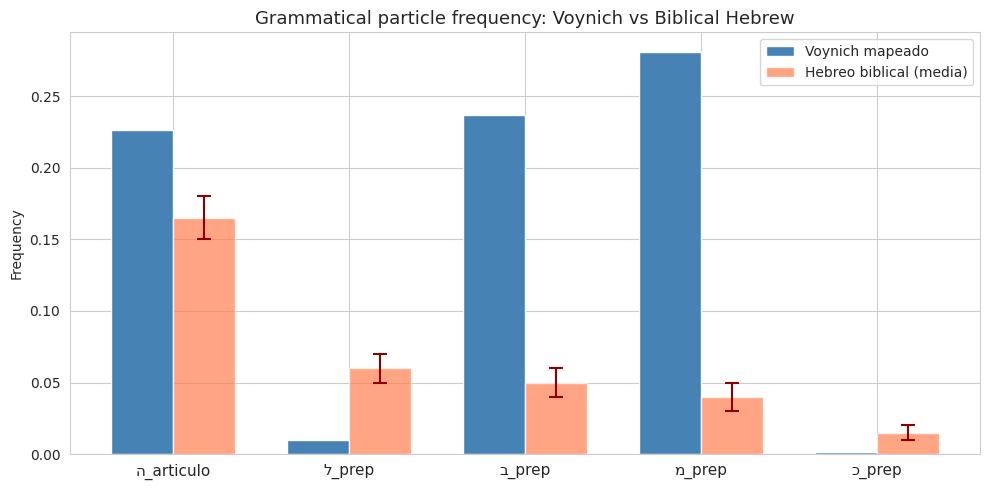


Particles within expected range: 0/5


In [7]:
# ── Grammatical particle frequencies ──

# In Biblical Hebrew, the approximate prefix frequencies are:
# ה (article): ~15-18% of words
# ל (to/for):  ~5-7%
# ב (in):      ~4-6%
# מ (from):    ~3-5%
# כ (as/like): ~1-2%

FREQ_HEBREO_BIBLICO = {
    'ה_articulo': (0.15, 0.18),
    'ל_prep':     (0.05, 0.07),
    'ב_prep':     (0.04, 0.06),
    'מ_prep':     (0.03, 0.05),
    'כ_prep':     (0.01, 0.02),
}

# Glyphs mapping to each Hebrew consonant
glifos_por_hebreo = defaultdict(set)
for g, h in mapping.items():
    glifos_por_hebreo[h].add(g)

total_palabras = len(palabras)

print("Glyphs mapping to grammatical particles:")
for part in ['ה', 'ל', 'ב', 'מ', 'כ']:
    glyphs = glifos_por_hebreo[part]
    print(f"  {part}: {', '.join(sorted(glyphs))}")

# Count words starting with each particle
conteo_prefijos = {}

glifos_he = glifos_por_hebreo['ה']
conteo_prefijos['ה_articulo'] = sum(1 for w in palabras if w[0] in glifos_he)

glifos_lamed = glifos_por_hebreo['ל']
conteo_prefijos['ל_prep'] = sum(1 for w in palabras if w[0] in glifos_lamed)

glifos_bet = glifos_por_hebreo['ב']
conteo_prefijos['ב_prep'] = sum(1 for w in palabras if w[0] in glifos_bet)

glifos_mem = glifos_por_hebreo['מ']
conteo_prefijos['מ_prep'] = sum(1 for w in palabras if w[0] in glifos_mem)

glifos_kaf = glifos_por_hebreo['כ']
conteo_prefijos['כ_prep'] = sum(1 for w in palabras if w[0] in glifos_kaf)

# ── Comparative table ──
print("\n── Grammatical particle frequency: mapped Voynich vs Biblical Hebrew ──\n")
comparacion_data = []
for part, rango in FREQ_HEBREO_BIBLICO.items():
    count = conteo_prefijos[part]
    freq_voynich = count / total_palabras
    lo, hi = rango
    dentro = lo <= freq_voynich <= hi
    comparacion_data.append({
        'particle': part,
        'count_voynich': count,
        'freq_voynich': f'{freq_voynich:.3f}',
        'Hebrew_range': f'{lo:.2f}-{hi:.2f}',
        'in_range': '✓' if dentro else '✗',
    })

df_comp = pd.DataFrame(comparacion_data)
print(df_comp.to_string(index=False))

# ── Visualisation ──
fig, ax = plt.subplots(figsize=(10, 5))
particulas = [d['particle'] for d in comparacion_data]
freqs_voynich = [conteo_prefijos[p] / total_palabras for p in particulas]
rangos_lo = [FREQ_HEBREO_BIBLICO[p][0] for p in particulas]
rangos_hi = [FREQ_HEBREO_BIBLICO[p][1] for p in particulas]

x = np.arange(len(particulas))
width = 0.35

bars = ax.bar(x, freqs_voynich, width, label='Voynich mapeado', color='steelblue')
ax.bar(x + width, [(lo+hi)/2 for lo, hi in zip(rangos_lo, rangos_hi)],
       width, label='Hebreo biblical (media)', color='coral', alpha=0.7)

for i, (lo, hi) in enumerate(zip(rangos_lo, rangos_hi)):
    mid = (lo + hi) / 2
    ax.errorbar(i + width, mid, yerr=[[mid-lo], [hi-mid]], color='darkred',
                capsize=5, capthick=1.5)

ax.set_xticks(x + width/2)
ax.set_xticklabels(particulas, fontsize=11)
ax.set_ylabel('Frequency')
ax.set_title('Grammatical particle frequency: Voynich vs Biblical Hebrew', fontsize=13)
ax.legend()
plt.tight_layout()
plt.savefig('images/semantic_particulas_freq.png', dpi=150, bbox_inches='tight')
plt.show()

n_dentro = sum(1 for d in comparacion_data if d['in_range'] == '✓')
print(f"\nParticles within expected range: {n_dentro}/{len(comparacion_data)}")

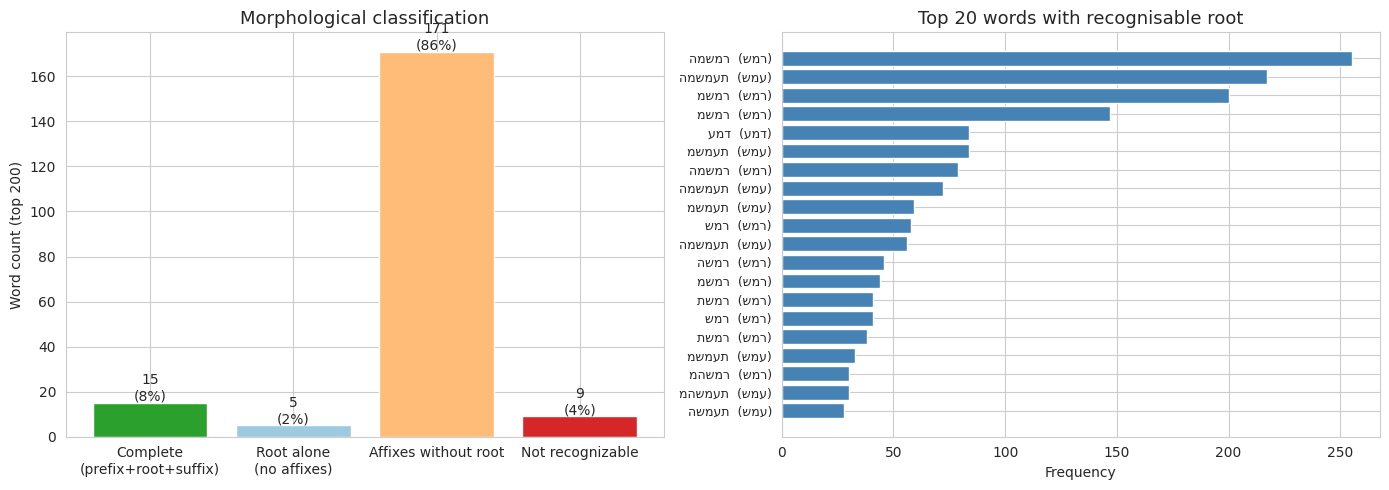


── Consecutive text fragment (first 30 words)──

   1. P2.A3.K1.A2.C2            → ימבתה
   2. A2.Q1.A3.B2               → תשמה
   3. A3.C1                     → מה
   4. Aa.Q2.A3.G1               → לשמר
   5. L1.A1.B2                  → במה
   6. L1.A1.C1.A2               → במהת
   7. U5.C2.J1.C2               → פהלה
   8. A2                        → ת
   9. Q1.A1.C1                  → שמה
  10. L1.A1.B2.B1.A2            → במהעת
  11. C2.A1.C1.A2               → המהת
  12. U1.A3.C1                  → עמה
  13. A1.C1.A2                  → מהת
  14. Q1.A3.F3                  → שמד
  15. K1.Q2.A3.G1               → בשמר
  16. L1.A3.C1                  → במה
  17. Aa.E1.C2                  → ליה
  18. U2.A3.C1                  → שמה
  19. U2.A3.C1                  → שמה
  20. B1.A3.E2                  → עמת
  21. C2.A2.A3.G3               → התמר
  22. L1.J1.Q1.A2               → בלשת
  23. A1.C1                     → מה
  24. A2.Q1.A3.G1               → תשמר
  25. L1.A1.B1               

In [8]:
# ── Morphological reconstruction visualisation ──

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barplot: category distribution
ax1 = axes[0]
cats = ['completa', 'raiz_parcial', 'morfologia_solo', 'no_reconocible']
cat_labels = ['Complete\n(prefix+root+suffix)', 'Root alone\n(no affixes)',
              'Affixes without root', 'Not recognizable']
cat_colors = ['#2ca02c', '#9ecae1', '#ffbb78', '#d62728']
vals = [cat_counts.get(c, 0) for c in cats]

bars = ax1.bar(cat_labels, vals, color=cat_colors)
for bar, val in zip(bars, vals):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{val}\n({val/len(df_morfo)*100:.0f}%)', ha='center', fontsize=10)
ax1.set_ylabel('Word count (top 200)')
ax1.set_title('Morphological classification', fontsize=13)

# Top 20 reconstructed "Hebrew words"
ax2 = axes[1]
reconocibles = df_morfo[df_morfo['categoria'].isin(['completa', 'raiz_parcial'])].head(20)
if len(reconocibles) > 0:
    y_pos = np.arange(len(reconocibles))
    ax2.barh(y_pos, reconocibles['freq'].values, color='steelblue')
    labels = [f"{row['hebreo']}  ({row['raiz']})" for _, row in reconocibles.iterrows()]
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(labels, fontsize=9)
    ax2.invert_yaxis()
    ax2.set_xlabel('Frequency')
    ax2.set_title('Top 20 words with recognisable root', fontsize=13)
else:
    ax2.text(0.5, 0.5, 'No recognizable words found',
             ha='center', va='center', transform=ax2.transAxes, fontsize=14)
    ax2.set_title('Top 20 words with recognisable root', fontsize=13)

plt.tight_layout()
plt.savefig('images/semantic_morfologia.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Example of consecutive mapped text fragment ──
print("\n── Consecutive text fragment (first 30 words)──\n")
for i, w in enumerate(palabras[:30]):
    glyph_str = '.'.join(w)
    hebrew_str = aplicar_mapping(w, mapping)
    print(f"  {i+1:2d}. {glyph_str:25s} → {hebrew_str}")

In [9]:
# ── Export results ──

# Helper to convert numpy/pandas int64 → native int
def to_native(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, dict):
        return {k: to_native(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_native(v) for v in obj]
    return obj

resultados = {
    'metadata': {
        'notebook': '10_semantic.ipynb',
        'description': 'Semantic analysis by section + morphological reconstruction',
        'conf_threshold': CONF_THRESHOLD,
        'n_palabras_global': len(palabras),
        'n_raices_referencia': len(HEBREW_ROOTS),
    },
    'roots_per_section': {
        sec: {r: int(c) for r, c in roots_por_seccion[sec].most_common()}
        for sec in SECCIONES_ORDEN
    },
    'roots_global': {r: int(c) for r, c in roots_global.most_common()},
    'totales_por_seccion': {k: int(v) for k, v in totales_por_seccion.items()},
    'semantic_correlation': {
        'chi2': float(chi2),
        'p_value': float(p_val),
        'dof': int(dof),
        'significativo': bool(p_val < 0.05),
        'correspondencias': correspondencia_resultados,
        'n_correspondencias_cumplidas': n_cumplen,
        'n_correspondencias_total': len(correspondencia_resultados),
    },
    'enrichment_per_category_section': {
        cat: {sec: float(enrichment_matrix[i, j])
              for j, sec in enumerate(SECCIONES_ORDEN)}
        for i, cat in enumerate(cat_names)
    },
    'morphological_analysis': {
        'distribucion': {k: int(v) for k, v in cat_counts.items()},
        'top50': to_native(
            df_morfo[['glifos', 'hebreo', 'prefijo', 'raiz', 'sufijo',
                       'categoria', 'freq']].head(50).to_dict(orient='records')
        ),
    },
    'particle_frequencies': {
        'voynich': {p: conteo_prefijos[p] / total_palabras for p in conteo_prefijos},
        'hebreo_biblico': {p: list(r) for p, r in FREQ_HEBREO_BIBLICO.items()},
        'comparacion': comparacion_data,
        'n_dentro_rango': n_dentro,
    },
}

out_path = 'semantic_resultados.json'
with open(out_path, 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2)

print(f"Results exported to {out_path}")
print(f"  Roots per section: {len(resultados['roots_per_section'])} sections")
print(f"  Chi²: {chi2:.2f}, p={p_val:.4e}")
print(f"  Correspondences met: {n_cumplen}/{len(correspondencia_resultados)}")
print(f"  Morphological categories: {dict(cat_counts)}")
print(f"  Particles within range: {n_dentro}/{len(comparacion_data)}")

Results exported to semantic_resultados.json
  Roots per section: 6 sections
  Chi²: 64.21, p=1.5600e-06
  Correspondences met: 4/6
  Morphological categories: {'morfologia_solo': np.int64(171), 'completa': np.int64(15), 'no_reconocible': np.int64(9), 'raiz_parcial': np.int64(5)}
  Particles within range: 0/5


## Conclusions

### Analysis 1: Roots by section

- **Heatmap**: shows the normalised distribution of the 30 most frequent roots
  across the 6 Voynich sections.
- **Semantic enrichment**: chi-squared test and enrichment by category × section.
- **Interpretation**: if the expected correspondences (herbal↔botanical,
  astronomical↔astronomy, etc.) show enrichment > 1, there is evidence that the
  mapping captures thematic semantics.

### Analysis 2: Morphological reconstruction

- **Classification**: what proportion of the 200 most frequent words shows
  recognisable Hebrew morphological structure (prefix + root + suffix).
- **Grammatical particles**: comparison of frequencies of ה, ב, כ, ל, מ
  as prefixes with real Biblical Hebrew frequencies.
- **Interpretation**: if particle frequencies fall within expected ranges,
  this constitutes independent morphosyntactic evidence.

### For the paper

- Results exported in `semantic_results.json`
- Figures: `semantic_heatmap_roots.png`, `semantic_enrichment_heatmap.png`,
  `semantic_particulas_freq.png`, `semantic_morfologia.png`
